# Activity 6.06 – Creating a Scatter Plot with Marginal Histograms



### 01: Import the necessary modules and enable plotting within a Jupyter Notebook


In [1]:
# Import settings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
%matplotlib inline


### 02: Filter the data so that you end up with samples containing a body mass and maximum longevity

The given dataset, AnAge, which was used in the previous exercise, is not complete. Select all of the samples of the **Aves** class with a body mass of less than **20,000**.


In [2]:
# Load dataset (local copy in the same folder)
data = pd.read_csv('anage_data.csv')
print('Original shape:', data.shape)

# Keep only samples that have a body mass and a maximum longevity
longevity = 'Maximum longevity (yrs)'
mass = 'Body mass (g)'
data = data[np.isfinite(data[longevity]) & np.isfinite(data[mass])]

# Select samples of the Aves class with a body mass of less than 20,000
aves = data[data['Class'] == 'Aves']
aves = aves[aves[mass] < 20000]
print('Aves (< 20000 g):', len(aves))


Original shape: (4218, 30)
Aves (< 20000 g): 166


### 03: Create a Figure with a constrained layout

Create a gridspec of size 4x4. Create a scatter plot of size 3x3 and marginal histograms of size 1x3 and 3x1. Add labels and a Figure title.


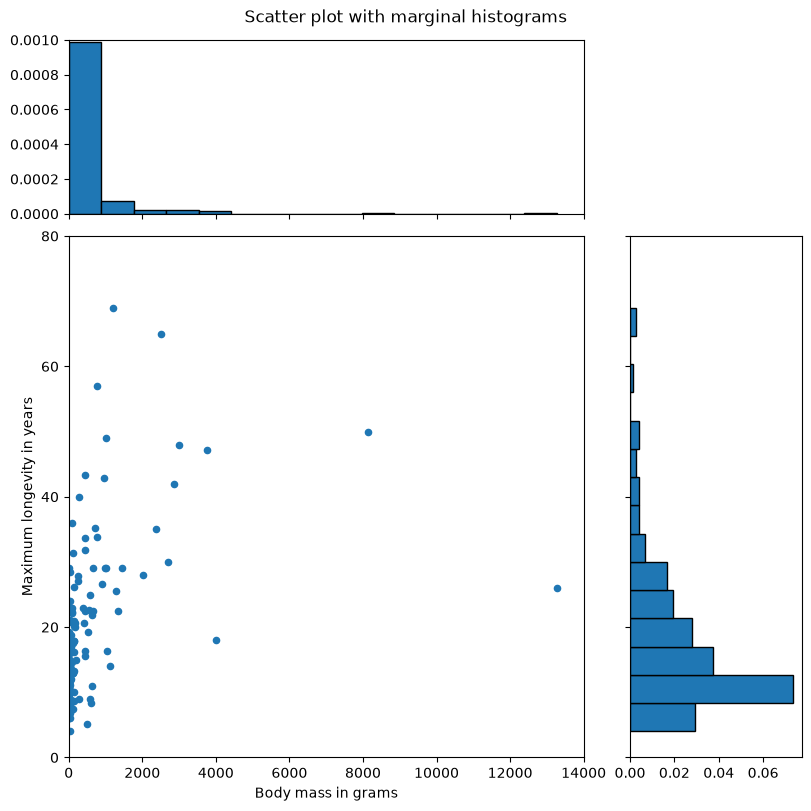

In [3]:
# Create figure with constrained layout
fig = plt.figure(figsize=(8, 8), constrained_layout=True)
# Create a 4x4 gridspec
gs = gridspec.GridSpec(4, 4, figure=fig)

# Scatter plot of size 3x3
ax_scatter = fig.add_subplot(gs[1:, :3])
ax_scatter.scatter(aves[mass], aves[longevity], s=20)
ax_scatter.set_xlabel('Body mass in grams')
ax_scatter.set_ylabel('Maximum longevity in years')
ax_scatter.set_xlim(0, 14000)
ax_scatter.set_ylim(0, 80)
ax_scatter.set_yticks(np.arange(0, 81, 20))

# Marginal histogram of size 1x3 (on top)
ax_hist_x = fig.add_subplot(gs[0, :3], sharex=ax_scatter)
ax_hist_x.hist(aves[mass], bins=15, density=True, edgecolor='black')
ax_hist_x.set_ylim(0, 0.0010)
ax_hist_x.set_yticks(np.arange(0, 0.0011, 0.0002))
ax_hist_x.tick_params(axis='x', labelbottom=False)

# Marginal histogram of size 3x1 (on the right)
ax_hist_y = fig.add_subplot(gs[1:, 3], sharey=ax_scatter)
ax_hist_y.hist(aves[longevity], bins=15, orientation='horizontal',
               density=True, edgecolor='black')
ax_hist_y.tick_params(axis='y', labelleft=False)

# Figure title
fig.suptitle('Scatter plot with marginal histograms')
plt.show()
